# Linear regression from the Gram matrix

For a Gaussian linear model $y = X\beta + \varepsilon$, $\varepsilon \sim \mathcal N(0, \sigma^2 I)$, expand the
residual sum of squares:

$$\lVert y - X\beta\rVert^2 = y^\top y - 2\beta^\top X^\top y + \beta^\top X^\top X\beta .$$

So $T = (n,\; X^\top X,\; X^\top y,\; y^\top y)$ is sufficient for $(\beta, \sigma)$. With $p$ predictors that is
$p(p+1)/2 + p + 2$ distinct numbers (the Gram matrix $X^\top X$ is symmetric), independent of $n$. The
log-likelihood is

$$\ell(\beta,\sigma) = -\tfrac n2 \log(2\pi\sigma^2) - \frac{y^\top y - 2\beta^\top X^\top y + \beta^\top X^\top X \beta}{2\sigma^2}.$$

Two practical consequences: the cost per gradient evaluation no longer depends on $n$, and the summaries are
additive, so they can be computed in SQL, in chunks or on separate machines and summed.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(505)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)
TIMINGS = []


def timed_fit(model, label, n_rows, case, kind, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    TIMINGS.append({"case": case, "kind": kind, "model": label, "rows": int(n_rows),
                    "wall_s": round(secs, 2), "min_ess_per_s": round(ess / secs, 1)})
    return idata


def save_timings(name):
    Path("timings").mkdir(exist_ok=True)
    Path(f"timings/{name}.json").write_text(json.dumps(TIMINGS, indent=1))
    return pd.DataFrame(TIMINGS).drop(columns="case")

## A million rows, ten predictors

Unlike the count models, nothing here requires categorical covariates. Continuous predictors are fine because
the sufficiency comes from the quadratic form of the Gaussian log-likelihood, not from grouping identical rows.
Predictors b1 and b2 are deliberately correlated.

In [2]:
n, p = 1_000_000, 10
X = np.column_stack([np.ones(n), rng.normal(size=(n, p - 1))])
X[:, 2] = 0.6 * X[:, 1] + 0.8 * X[:, 2]                       # b1 and b2 correlated
beta_true = rng.normal(0, 0.5, p)
sigma_true = 2.0
y = X @ beta_true + rng.normal(0, sigma_true, n)

The summaries are computed in ten chunks. Each chunk could live in a different file or partition; only one is
needed in memory at a time. We keep the running totals after each chunk for a figure below.

In [3]:
XtX, Xty, yty, n_seen = np.zeros((p, p)), np.zeros(p), 0.0, 0
running = []
for Xc, yc in zip(np.array_split(X, 10), np.array_split(y, 10)):
    XtX, Xty, yty, n_seen = XtX + Xc.T @ Xc, Xty + Xc.T @ yc, yty + yc @ yc, n_seen + len(yc)
    running.append((XtX.copy(), Xty.copy(), yty, n_seen))
print(f"{n:,} x {p} design -> {XtX.size + Xty.size + 2} stored numbers ({p * (p + 1) // 2 + p + 2} distinct)")

1,000,000 x 10 design -> 112 stored numbers (67 distinct)


The compressed model writes the log-likelihood above directly with `pm.Potential`. Unlike the count cases there
is no standard distribution whose observed value is $(X^\top X, X^\top y, y^\top y)$, so the `Potential` is the
simplest route. The cost is that the model has no pointwise log-likelihood for leave-one-out cross-validation.

In [4]:
coords = {"coef": [f"b{j}" for j in range(p)]}

with pm.Model(coords=coords) as lm_full:
    beta = pm.Normal("beta", 0, 2, dims="coef")
    sigma = pm.HalfNormal("sigma", 5)
    pm.Normal("y", X @ beta, sigma, observed=y)

with pm.Model(coords=coords) as lm_suff:
    beta = pm.Normal("beta", 0, 2, dims="coef")
    sigma = pm.HalfNormal("sigma", 5)
    rss = yty - 2 * beta @ Xty + beta @ XtX @ beta
    pm.Potential("loglik", -0.5 * n * pm.math.log(2 * np.pi * sigma**2) - rss / (2 * sigma**2))

idata_full = timed_fit(lm_full, "Normal, 1M raw rows", n, "Linear regression", "raw")
idata_suff = timed_fit(lm_suff, "Potential on (n, X'X, X'y, y'y)", 1, "Linear regression", "compressed")

NUTS[nutpie]: [beta, sigma]
NUTS[nutpie]: [beta, sigma]


## What the Gram matrix encodes

With a flat prior the posterior for $\beta$ is centred on the least-squares estimate
$\hat\beta = (X^\top X)^{-1}X^\top y$ with covariance $\hat\sigma^2 (X^\top X)^{-1}$. So the Gram matrix is, up to
$\hat\sigma^2$, the posterior precision. The correlation built into b1 and b2 shows up as the tilt of their joint
posterior, in both fits and in the closed form.

The right panel uses additivity. After each chunk, the running totals give the closed-form estimate and interval
for b1 and b2 from the data seen so far, with $\hat\sigma^2 = (y^\top y - \hat\beta^\top X^\top y)/(n - p)$. The
intervals shrink as chunks are added, and the last point is the full-data answer.

In [5]:
def ols(XtX_, Xty_, yty_, n_):
    bhat = np.linalg.solve(XtX_, Xty_)
    s2 = (yty_ - bhat @ Xty_) / (n_ - p)
    return bhat, s2 * np.linalg.inv(XtX_)

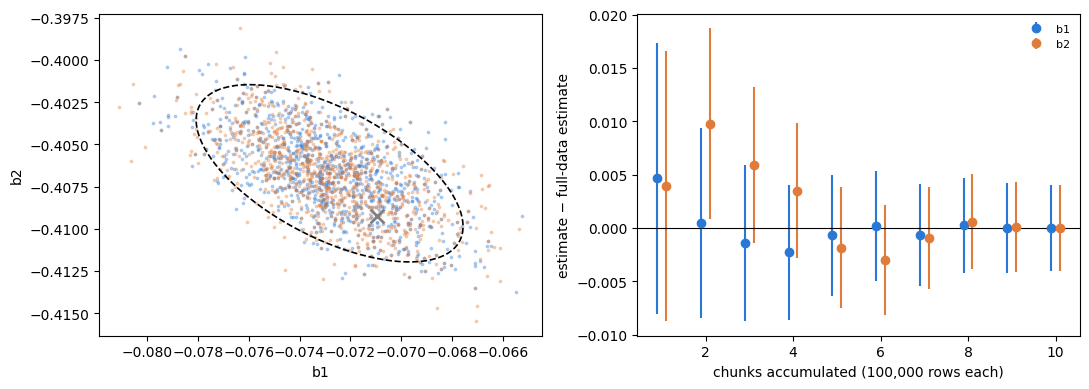

In [6]:
#| label: fig-lm-use
#| fig-cap: "Left: joint posterior of b1 and b2 from raw rows (blue points) and from the Gram matrix (orange points), with the closed-form 89% ellipse from σ̂²(XᵀX)⁻¹ in black; the true value is the grey cross. Right: closed-form estimate and 89% interval for b1 and b2 from the running totals after each of ten chunks, shown relative to the full-data estimate."
from scipy.stats import chi2
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
for idata, col in [(idata_full, "#2a78d6"), (idata_suff, "#e07b39")]:
    b = idata.posterior["beta"].sel(coef=["b1", "b2"]).values.reshape(-1, 2)
    ax.scatter(b[::4, 0], b[::4, 1], s=3, alpha=0.3, color=col)
bhat, cov = ols(XtX, Xty, yty, n)
vals, vecs = np.linalg.eigh(cov[1:3, 1:3])
theta = np.linspace(0, 2 * np.pi, 200)
ell = vecs @ (np.sqrt(vals * chi2.ppf(0.89, 2))[:, None] * np.array([np.cos(theta), np.sin(theta)]))
ax.plot(bhat[1] + ell[0], bhat[2] + ell[1], "k--", lw=1.2)
ax.plot(beta_true[1], beta_true[2], "x", color="grey", ms=10, mew=2)
ax.set_xlabel("b1")
ax.set_ylabel("b2")
ax = axes[1]
est = [ols(*r) for r in running]
for j, col, off in [(1, "#2a78d6", -0.1), (2, "#e07b39", 0.1)]:
    m = np.array([e[0][j] for e in est]) - bhat[j]
    sd = np.array([np.sqrt(e[1][j, j]) for e in est])
    x = np.arange(1, 11) + off
    ax.errorbar(x, m, yerr=1.6 * sd, fmt="o", color=col, label=f"b{j}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("chunks accumulated (100,000 rows each)")
ax.set_ylabel("estimate − full-data estimate")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Raw rows vs the Gram matrix

At a million rows every interval is very narrow, so plotting the two posteriors side by side shows little. The
figure instead shows the difference between the two fits' posterior means, in units of the raw-row posterior
standard deviation. Differences of a few hundredths of a standard deviation are Monte Carlo noise.

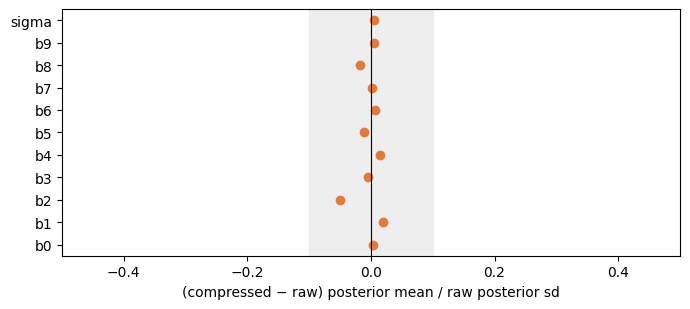

In [7]:
#| label: fig-lm-equiv
#| fig-cap: "Difference between posterior means from the Gram-matrix fit and the raw-row fit, divided by the raw-row posterior standard deviation, for every parameter."
sf = az.summary(idata_full, var_names=["beta", "sigma"])
ss = az.summary(idata_suff, var_names=["beta", "sigma"])
z = (ss["mean"].values - sf["mean"].values) / sf["sd"].values
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axvspan(-0.1, 0.1, color="#eeeeee")
ax.plot(z, np.arange(p + 1), "o", color="#e07b39")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(np.arange(p + 1), list(coords["coef"]) + ["sigma"])
ax.set_xlim(-0.5, 0.5)
ax.set_xlabel("(compressed − raw) posterior mean / raw posterior sd")
plt.tight_layout()
plt.show()

In [8]:
#| label: tbl-lm-speed
#| tbl-cap: "One million rows vs 112 stored numbers."
save_timings("05_linear_regression_gram")

,kind,model,rows,wall_s,min_ess_per_s
0,raw,"Normal, 1M raw rows",1000000,186.44,22.7
1,compressed,"Potential on (n, X'X, X'y, y'y)",1,0.67,6379.2


## What compression gives up, and extensions

- **Residual diagnostics.** As with any `pm.Potential`, there is no pointwise log-likelihood or posterior predictive
  for individual rows. Residual checks must be computed on the raw data, chunk by chunk.
- **Robust likelihoods.** A Student-$t$ error has no fixed-dimension sufficient statistic. By the
  Pitman–Koopman–Darmois theorem, when the support does not depend on the parameters, only exponential families
  have one. Approximate summaries are covered in notebook 06.
- **Grouped regressions.** Keep one $(n_g, X_g^\top X_g, X_g^\top y_g, y_g^\top y_g)$ per group. Varying intercepts and
  slopes become a sum of per-group quadratic forms, and the cost scales with the number of groups.
- **Weights.** Weighted least squares and group-specific variances work the same way with $X^\top W X$.